# Mutational dynamics of 9-mers.

In [1]:
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LinearSegmentedColormap, Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable

import seaborn as sn

from scripts.functions import mutation_matrix as mm
from scripts.functions import plotting as plo
from scripts.functions import Gillespie_algorithm as ga
from scripts.functions.colors import shm_colors
color_red = shm_colors['color_red']
color_blue = shm_colors['color_blue']
color_violet = shm_colors['color_violet']
color_gray = shm_colors['color_gray']

muts = pd.read_csv('data/Spisak_mutabilities_context.tsv', sep ="\t")

l_seq = 9
l_context = 2
sequences = mm.generate_all_sequences(l_seq)
mutation_matrix_sp = mm.compute_mutmatrix(sequences, muts, l_seq, l_context)
sequence_to_index = {seq: idx for idx, seq in enumerate(sequences)}

conn_dict_kmer = mm.connectivity(sequences)

# k-mers
right_eigvals_real, stat_freq_norm, v1, v2 = mm.k_eigenvectors_phased(10, mutation_matrix_sp, sequences)
## rotate v2 so CCCCTGGGG lies on the positive imaginary axis
target_seq = 'CCCCTGGGG'
target_idx = np.where(np.asarray(sequences) == target_seq)[0][0]
z = v2[target_idx]
if np.isclose(np.abs(z), 0):
    raise ValueError(f"{target_seq} is too close to the origin to define a rotation.")
## desired angle = 0 degrees = positive imaginary axis
target_angle = 0.0
## rotation angle
theta = target_angle - np.angle(z)
## rotate the entire complex eigenvector
v2 = v2 * np.exp(1j * theta)

100%|██████████| 589824/589824 [00:01<00:00, 470967.73it/s]


## a: Distribution of all possible 9-mers along diffusion axis 1 and their natural log stationary frequencies.

Sequences containing hot-spot (WRC, red, left) or cold-spot (SYC, blue, right) motifs are highlighted. Marginal histograms show the distribution of log stationary frequencies for motif-containing sequences. Dashed horizontal lines show the median of the corresponding distribution. The inset demonstrates how each plotted point represents cyclic rotations of the same sequence, which all share the same stationary frequency and the same position along diffusion axis 1.

In [2]:
## defining what counts as hot- and cold-spots
hotspots4 = ['AACC', 'AACT', 'AGCC', 'AGCT', 'TACC', 'TACT', 'TGCC', 'TGCT']
coldspots3 = ['GCC', 'GTC', 'CCC', 'CTC']
hotspots3_WRC = ['AAC', 'AGC', 'TAC', 'TGT']
hotspots2_WA = ['TA', 'AA']

## creating a dataframe with all the data
kmers_df = pd.DataFrame(columns = ['seq_id', 'sequence', 'log stat freq', 'v1.real', 'v2.real', 'v2.imag', 'hs', 'cs'])
kmers_df['seq_id'] = list(range(len(sequences)))
kmers_df['sequence'] = sequences
kmers_df['log stat freq'] = np.log(stat_freq_norm.real)
kmers_df['v1.real'] = v1.real
kmers_df['v2.real'] = v2.real
kmers_df['v2.imag'] = v2.imag
kmers_df['hs'] = 'no'
kmers_df['cs'] = 'no'
kmers_df['subs_rate'] = -mutation_matrix_sp.diagonal()

## marking the hot- and cold-spots
for hs, cs in zip(hotspots3_WRC, coldspots3):
    kmers_df.loc[kmers_df["sequence"].str.contains(hs), "hs"] = "yes"
    kmers_df.loc[kmers_df["sequence"].str.contains(cs), "cs"] = "yes"

## creating custom palette with slightly jittered colors to flash out separate dots
hs_len = len(kmers_df[kmers_df['hs'] == 'yes'])
cs_len = len(kmers_df[kmers_df['cs'] == 'yes'])
### jittered colors
all_dots = plo.normal_palette(color_gray,  n=len(kmers_df), sigma_h=0, sigma_s=0, sigma_v=0.025, seed=123)
hs_colors = plo.normal_palette(color_red,  n=hs_len, sigma_h=0, sigma_s=0.05, sigma_v=0, seed=123)
cs_colors = plo.normal_palette(color_blue, n=cs_len, sigma_h=0, sigma_s=0.05, sigma_v=0, seed=123)
### adding colors to the dataframe
kmers_df['color_hs'] = all_dots
kmers_df['color_cs'] = all_dots
kmers_df.loc[kmers_df['hs'] == 'yes', 'color_hs'] = hs_colors
kmers_df.loc[kmers_df['cs'] == 'yes', 'color_cs'] = cs_colors

## colormap for substitution rate
custom_cmap = LinearSegmentedColormap.from_list("my_cmap", [color_blue, color_red])
norm = Normalize(vmin=kmers_df['subs_rate'].min(), vmax=kmers_df['subs_rate'].max())
vals = kmers_df['subs_rate'].to_numpy()
rgba = custom_cmap(norm(vals))
kmers_df['subs_color'] = list(map(tuple, rgba))
kmers_df['color'] = all_dots

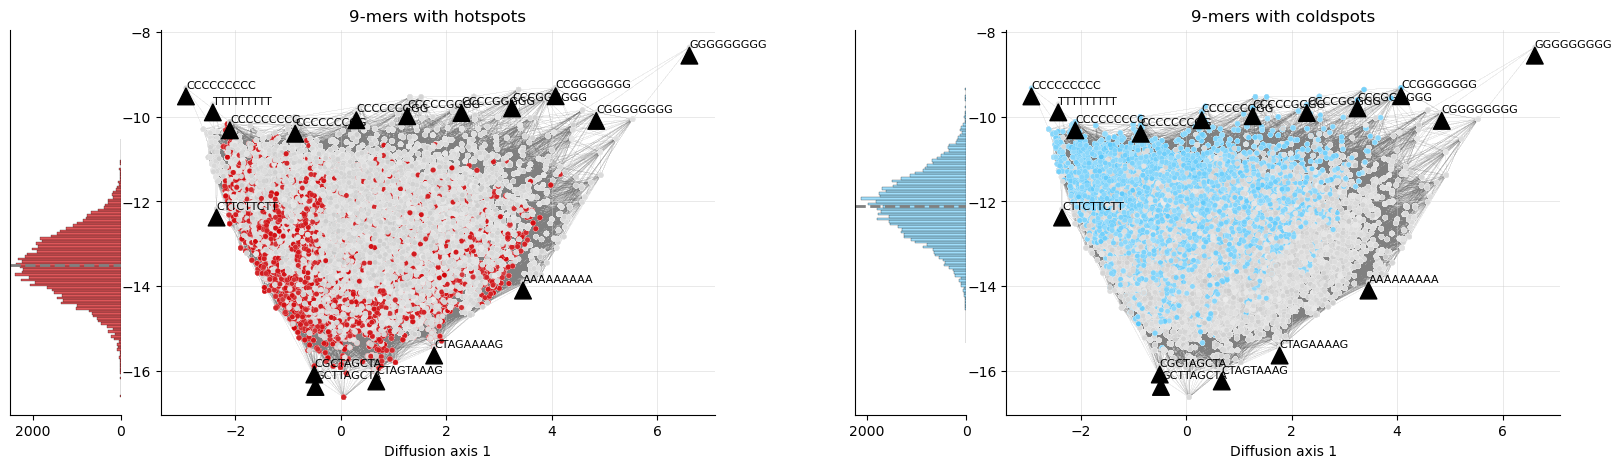

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(20, 5))

## which sequences will be annotated on the plot
to_annotate = [['A']*l_seq, ['T']*l_seq, ['G']*l_seq, ['C']*l_seq]
for i in range(1, l_seq):
    to_annotate.append((['C']*(l_seq-i) + ['G']*i))
to_annotate.append(['C', 'T', 'T', 'C', 'T', 'T', 'C', 'T', 'T'])
to_annotate.append(['G', 'C', 'T', 'T', 'A', 'G', 'C', 'T', 'A'])
to_annotate.append(['C', 'G', 'C', 'T', 'A', 'G', 'C', 'T', 'A'])
to_annotate.append(['C', 'T', 'A', 'G', 'A', 'A', 'A', 'A', 'G'])
to_annotate.append(['C', 'T', 'A', 'G', 'T', 'A', 'A', 'A', 'G'])

## which axes to plot and how to sort them
vis_x = 'v1.real'
vis_y = 'log stat freq'
kmers_df_sorted = kmers_df.sort_values(by = 'v2.real').reset_index(drop = True)
## edges underneath
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[0], color="gray", linewidth=0.1, alpha=0.1)
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[1], color="gray", linewidth=0.1, alpha=0.1)

## hotspots
ax0 = axes[0]
divider = make_axes_locatable(ax0)
ax0_hist = divider.append_axes("left", size="20%", pad=0.4, sharey=ax0)

ax0.scatter(data = kmers_df_sorted, x = vis_x, y = vis_y , s=14, c = kmers_df_sorted['color_hs'],
                alpha=1, edgecolor="white", linewidth=0.1, zorder=2, rasterized = True)

sn.histplot(data = kmers_df_sorted[(kmers_df_sorted['hs'] == 'yes') & (kmers_df_sorted['cs'] != 'yes')],
            y=vis_y, ax=ax0_hist, bins=100, color = color_red)
hs_median = np.median(kmers_df_sorted[(kmers_df_sorted['hs'] == 'yes') & (kmers_df_sorted['cs'] != 'yes')]['log stat freq'])
ax0_hist.axhline(hs_median, color='gray', linestyle='--', linewidth=2)

plt.setp(ax0_hist.get_yticklabels(), visible=False)
ax0_hist.invert_xaxis()
ax0_hist.set_ylabel(None)
ax0_hist.set_xlabel(None)
ax0_hist.tick_params(axis='y', left=False)

for item in to_annotate:
    item = ''.join(item)
    coords_x = kmers_df_sorted[vis_x][kmers_df_sorted['sequence'] == item].iloc[0]
    coords_y = kmers_df_sorted[vis_y][kmers_df_sorted['sequence'] == item].iloc[0]
    axes[0].annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                 arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                 fontsize=8, color='black')

## coldspots
ax1 = axes[1]
divider = make_axes_locatable(ax1)
ax1_hist = divider.append_axes("left", size="20%", pad=0.4, sharey=ax1)
cs_median = np.median(kmers_df_sorted[(kmers_df_sorted['cs'] == 'yes') & (kmers_df_sorted['hs'] != 'yes')]['log stat freq'])
ax1_hist.axhline(cs_median, color='gray', linestyle='--', linewidth=2)

ax1.scatter(data = kmers_df_sorted, x = vis_x, y = vis_y , s=14, c = kmers_df_sorted['color_cs'],
                alpha=1, edgecolor="white", linewidth=0.1, zorder=2, rasterized = True)

sn.histplot(data=kmers_df_sorted[(kmers_df_sorted['cs'] == 'yes') & (kmers_df_sorted['hs'] != 'yes')], y=vis_y, ax=ax1_hist, bins=100, color = color_blue)
plt.setp(ax1_hist.get_yticklabels(), visible=False)
ax1_hist.invert_xaxis()
ax1_hist.set_ylabel(None)
ax1_hist.set_xlabel(None)
ax1_hist.tick_params(axis='y', left=False)

for item in to_annotate:
    item = ''.join(item)
    coords_x = kmers_df_sorted[vis_x][kmers_df_sorted['sequence'] == item].iloc[0]
    coords_y = kmers_df_sorted[vis_y][kmers_df_sorted['sequence'] == item].iloc[0]
    axes[1].annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                 arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                 fontsize=8, color='black')

for ax in axes:
    ax.set_xlabel("Diffusion axis 1")
axes[0].set_ylabel("Log stationary distribution")

axes[0].set_title("9-mers with hotspots")
axes[1].set_title("9-mers with coldspots")
axes[0].grid(True, alpha=0.6, color = '#CCCCCC')
axes[1].grid(True, alpha=0.6, color = '#CCCCCC')
sn.despine()

## b: Distribution of all possible 9-mers along diffusion axis 1 and the real component of diffusion axis 2.

9-mers are colored by their total substitution rate.

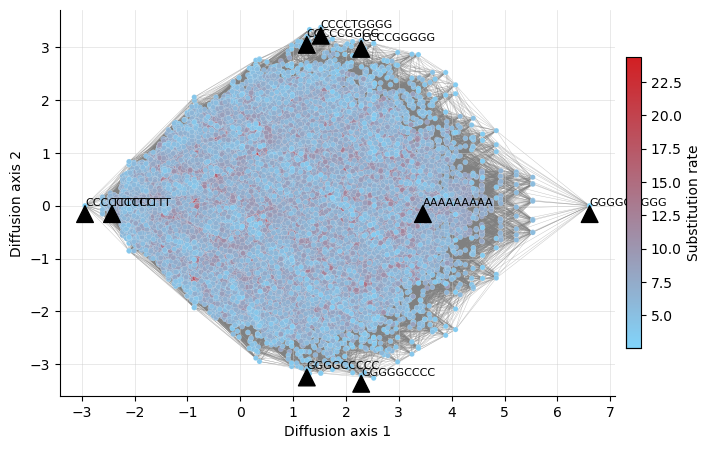

In [4]:
fig, axes = plt.subplots(1, 1, figsize=(7.5, 7.5))

## which sequences to annotate
to_annotate = ['CCCCGGGGG', 'GGGGCCCCC', 'CCCCCGGGG', 'GGGGGCCCC', 'CCCCTGGGG',
               ['A']*l_seq, ['T']*l_seq, ['G']*l_seq, ['C']*l_seq]

## axes that are used for sorting and plotting
kmers_df_sorted = kmers_df_sorted.sort_values(by = 'v2.imag', ascending=False).reset_index(drop = True)
vis_x = 'v1.real'
vis_y = 'v2.real'

## edges underneath
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes, color="gray", linewidth=0.3, alpha=0.5)

axes.scatter(data = kmers_df_sorted, x = vis_x, y = vis_y , s=14, c = 'subs_color',
                alpha=1, edgecolor="white", linewidth=0.1, zorder=2, rasterized = True)

for item in to_annotate:
    item = ''.join(item)
    coords_x = kmers_df_sorted[vis_x][kmers_df_sorted['sequence'] == item].iloc[0]
    coords_y = kmers_df_sorted[vis_y][kmers_df_sorted['sequence'] == item].iloc[0]
    axes.annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                 arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                 fontsize=8, color='black')
axes.set_xlabel("Diffusion axis 1")
axes.set_ylabel("Diffusion axis 2")

sm = plt.cm.ScalarMappable(cmap=custom_cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axes, location="right", fraction=0.025, pad=0.02)
cbar.set_label("Substitution rate")
axes.set_aspect('equal', adjustable='box')
axes.grid(True, alpha=0.6, color = '#CCCCCC')
axes.xaxis.set_major_locator(MultipleLocator(1))
axes.yaxis.set_major_locator(MultipleLocator(1))

sn.despine()

100 simulated mutation trajectories, each run until $t = 1$ from starting sequences CCCCGGGGG (left) and AGCTAAGCT (right).

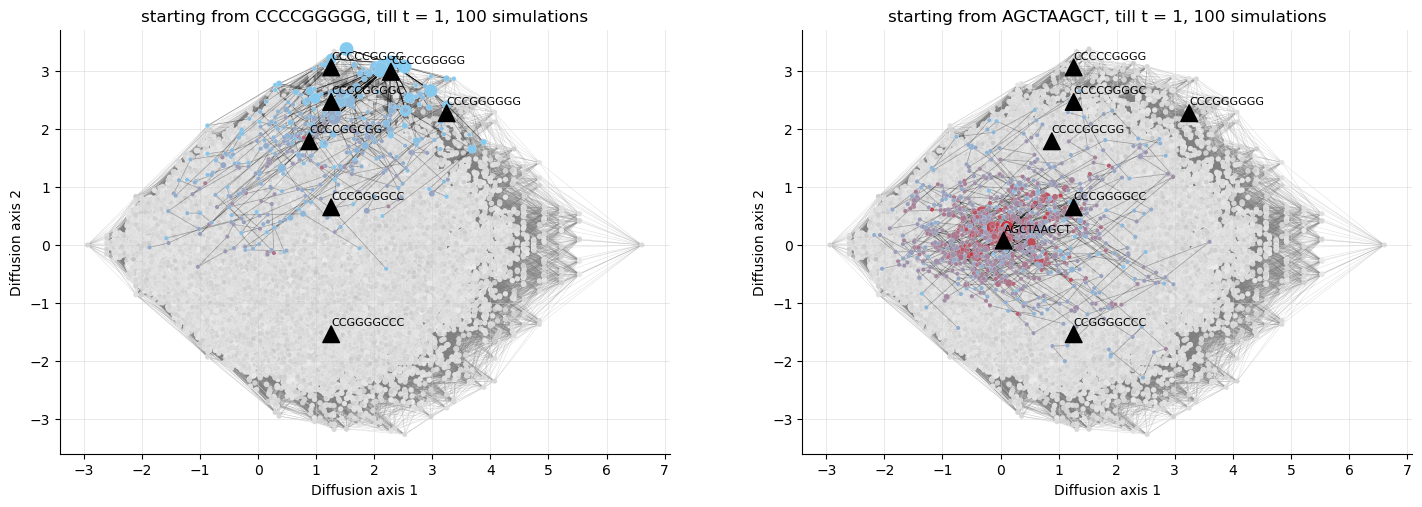

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

## axes to plot
vis_x = 'v1.real'
vis_y = 'v2.real'
## simulation parameters
time_stop = 1
n_repeats = 100

## plotting all edges
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[0], color='gray', linewidth=0.3, alpha=0.3)
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[1], color='gray', linewidth=0.3, alpha=0.3)

## sequences to annotate
to_annotate = ['CCCCCGGGG', 'CCCGGGGGG', 'CCCCGGGGC', 'CCCGGGGCC', 'CCGGGGCCC', 'CCCCGGCGG']
start_seqs = ['CCCCGGGGG', 'AGCTAAGCT']

for start_seq, ax in zip(start_seqs, axes):

    ### LEFT panel: poly-C-G
    seqs_array, times_array = ga.mut_trajectory(start_seq, n_repeats, mutation_matrix_sp, time_stop = time_stop)
    connect_paths = plo.path_edges(seqs_array, sequence_to_index)

    ### counting and counting visiting sequences
    visited = dict()
    for path in seqs_array:
        for seq in path:
            seq_idx = sequence_to_index[seq]
            if seq_idx not in visited.keys():
                visited[seq_idx] = 1
            else:
                seq_idx = sequence_to_index[seq]
                visited[seq_idx] += 1
    visited = pd.DataFrame(visited, index = [0]).T.reset_index()
    visited.columns = ['seq_id', 'visited']
    visited = visited.merge(kmers_df, on = 'seq_id', how = 'left')
    visited.loc[visited['sequence'] == start_seq, 'visited'] -= n_repeats
    #### to increase dot size
    visited['visited'] = visited['visited'] * 10
    visited_colors = plo.normal_palette(color_violet,  n=len(visited), sigma_h=0, sigma_s=0.05, sigma_v=0, seed=123)
    visited['color'] = visited_colors

    ### plotting visited trajectory
    for path in connect_paths:
        edge_x = []
        edge_y = []
        for key in path.keys():
            xval = kmers_df[vis_x][kmers_df['seq_id'] == key].iloc[0]
            yval = kmers_df[vis_y][kmers_df['seq_id'] == key].iloc[0]
            edge_x.append(xval)
            edge_y.append(yval)
        ## edges underneath
        plo.add_edges(path, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(), ax=ax, color="black", linewidth=0.5, alpha=0.3, zorder = 2)

    ax.scatter(data = kmers_df, x = vis_x, y = vis_y , s=14, c = kmers_df['color'],
                    alpha=1, edgecolor="white", linewidth=0.1, zorder=1, rasterized=True)

    ax.scatter(data = visited, x = vis_x, y = vis_y , s = 'visited', c = visited['subs_color'],
                    alpha=1, edgecolor="white", linewidth=0.1, zorder=3, rasterized=True)

    for item in to_annotate:
        item = ''.join(item)
        coords_x = kmers_df[vis_x][kmers_df['sequence'] == item].iloc[0]
        coords_y = kmers_df[vis_y][kmers_df['sequence'] == item].iloc[0]
        ax.annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                     arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                     fontsize=8, color='black')

    coords_x = kmers_df[vis_x][kmers_df['sequence'] == start_seq].iloc[0]
    coords_y = kmers_df[vis_y][kmers_df['sequence'] == start_seq].iloc[0]
    ax.annotate(start_seq, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                arrowprops=dict(width = 1, facecolor='black', shrink=0.05), fontsize=8, color='black')
    ax.set_title(f'starting from {start_seq}, till t = {time_stop}, {n_repeats} simulations')

    ax.set_xlabel('Diffusion axis 1')
    ax.set_ylabel('Diffusion axis 2')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.6, color = '#CCCCCC')
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))

sn.despine()
plt.tight_layout()

## c: Distribution of all possible 9-mers along diffusion axis 2 real and imaginary components.

9-mers are colored by their total substitution rate.

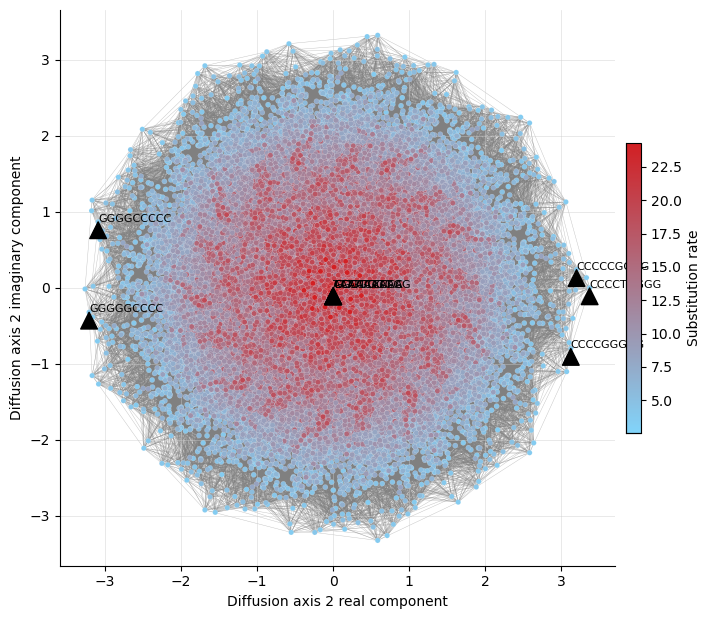

In [6]:
fig, axes = plt.subplots(1, 1, figsize=(7.5, 7.5))

## which sequences to annotate
to_annotate = ['CCCCGGGGG', 'GGGGCCCCC', 'CCCCCGGGG', 'GGGGGCCCC', 'CCCCTGGGG',
               ['A']*l_seq, ['T']*l_seq, ['G']*l_seq, ['C']*l_seq]

## axes that are used for sorting and plotting
kmers_df_sorted = kmers_df_sorted.sort_values(by = 'log stat freq', ascending = False).reset_index(drop = True)
vis_x = 'v2.real'
vis_y = 'v2.imag'

## edges underneath
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes, color="gray", linewidth=0.3, alpha=0.5)

axes.scatter(data = kmers_df_sorted, x = vis_x, y = vis_y , s=14, c = 'subs_color',
                alpha=1, edgecolor="white", linewidth=0.1, zorder=2, rasterized = True)

for item in to_annotate:
    item = ''.join(item)
    coords_x = kmers_df_sorted[vis_x][kmers_df_sorted['sequence'] == item].iloc[0]
    coords_y = kmers_df_sorted[vis_y][kmers_df_sorted['sequence'] == item].iloc[0]
    axes.annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                 arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                 fontsize=8, color='black')
axes.set_xlabel("Diffusion axis 2 real component")
axes.set_ylabel("Diffusion axis 2 imaginary component")

sm = plt.cm.ScalarMappable(cmap=custom_cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axes, location="right", fraction=0.025, pad=0.02)
cbar.set_label("Substitution rate")
axes.set_aspect('equal', adjustable='box')
axes.grid(True, alpha=0.6, color = '#CCCCCC')
axes.xaxis.set_major_locator(MultipleLocator(1))
axes.yaxis.set_major_locator(MultipleLocator(1))

sn.despine()

 Left and right: 100 simulated mutation trajectories, each run until $t = 1$ from starting sequences CCCCGGGGG (left) and AGCTAAGCT (right).

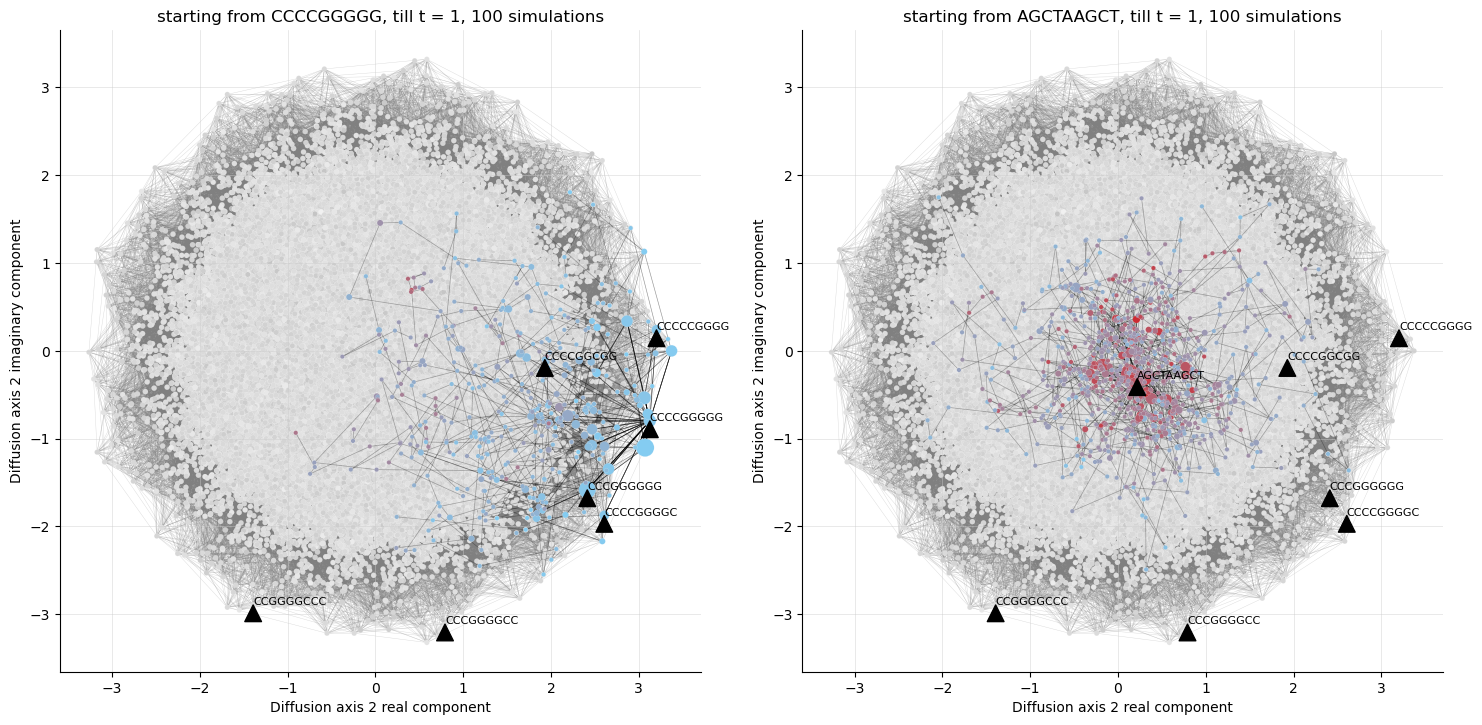

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

## axes to plot
vis_x = 'v2.real'
vis_y = 'v2.imag'
## simulation parameters
time_stop = 1
n_repeats = 100

## plotting all edges
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[0], color='gray', linewidth=0.3, alpha=0.3)
plo.add_edges(conn_dict_kmer, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(),
              ax=axes[1], color='gray', linewidth=0.3, alpha=0.3)

## sequences to annotate
to_annotate = ['CCCCCGGGG', 'CCCGGGGGG', 'CCCCGGGGC', 'CCCGGGGCC', 'CCGGGGCCC', 'CCCCGGCGG']
start_seqs = ['CCCCGGGGG', 'AGCTAAGCT']

for start_seq, ax in zip(start_seqs, axes):

    ### LEFT panel: poly-C-G
    seqs_array, times_array = ga.mut_trajectory(start_seq, n_repeats, mutation_matrix_sp, time_stop = time_stop)
    connect_paths = plo.path_edges(seqs_array, sequence_to_index)

    ### counting and counting visiting sequences
    visited = dict()
    for path in seqs_array:
        for seq in path:
            seq_idx = sequence_to_index[seq]
            if seq_idx not in visited.keys():
                visited[seq_idx] = 1
            else:
                seq_idx = sequence_to_index[seq]
                visited[seq_idx] += 1
    visited = pd.DataFrame(visited, index = [0]).T.reset_index()
    visited.columns = ['seq_id', 'visited']
    visited = visited.merge(kmers_df, on = 'seq_id', how = 'left')
    visited.loc[visited['sequence'] == start_seq, 'visited'] -= n_repeats
    #### to increase dot size
    visited['visited'] = visited['visited'] * 10
    visited_colors = plo.normal_palette(color_violet,  n=len(visited), sigma_h=0, sigma_s=0.05, sigma_v=0, seed=123)
    visited['color'] = visited_colors

    ### plotting visited trajectory
    for path in connect_paths:
        edge_x = []
        edge_y = []
        for key in path.keys():
            xval = kmers_df[vis_x][kmers_df['seq_id'] == key].iloc[0]
            yval = kmers_df[vis_y][kmers_df['seq_id'] == key].iloc[0]
            edge_x.append(xval)
            edge_y.append(yval)
        ## edges underneath
        plo.add_edges(path, kmers_df[vis_x].to_numpy(), kmers_df[vis_y].to_numpy(), ax=ax, color="black", linewidth=0.5, alpha=0.3, zorder = 2)

    ax.scatter(data = kmers_df, x = vis_x, y = vis_y , s=14, c = kmers_df['color'],
                    alpha=1, edgecolor="white", linewidth=0.1, zorder=1, rasterized=True)

    ax.scatter(data = visited, x = vis_x, y = vis_y , s = 'visited', c = visited['subs_color'],
                    alpha=1, edgecolor="white", linewidth=0.1, zorder=3, rasterized=True)

    for item in to_annotate:
        item = ''.join(item)
        coords_x = kmers_df[vis_x][kmers_df['sequence'] == item].iloc[0]
        coords_y = kmers_df[vis_y][kmers_df['sequence'] == item].iloc[0]
        ax.annotate(item, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                     arrowprops=dict(width = 1, facecolor='black', shrink=0.05),
                     fontsize=8, color='black')

    coords_x = kmers_df[vis_x][kmers_df['sequence'] == start_seq].iloc[0]
    coords_y = kmers_df[vis_y][kmers_df['sequence'] == start_seq].iloc[0]
    ax.annotate(start_seq, xy=(coords_x, coords_y), xytext=(coords_x, coords_y),
                arrowprops=dict(width = 1, facecolor='black', shrink=0.05), fontsize=8, color='black')
    ax.set_title(f'starting from {start_seq}, till t = {time_stop}, {n_repeats} simulations')

    ax.set_xlabel('Diffusion axis 2 real component')
    ax.set_ylabel('Diffusion axis 2 imaginary component')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.6, color = '#CCCCCC')
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(1))

sn.despine()
plt.tight_layout()